# Mapping Seto Inland Sea River Discharge & Water Level Stations

This notebook reads the scraped and filtered river stations from the Seto Inland Sea region
(`sis_river_water_stations.csv`) and visualizes them on a high-resolution regional Cartopy map.

### Objectives
1. **Load** the filtered river observation stations dataset.
2. **Convert** the tabular data into a spatial GeoDataFrame.
3. **Visualize** the geographic locations of these stations overlaying the high-resolution Seto Inland Sea landmass boundary (`Setonaikai_boundary_2.shp`).
4. **Format** the output using the project's standardized `MappingConfig` styling.

In [1]:
import sys
import os
from pathlib import Path

# Ensure project root is in sys.path
project_root = Path(os.getcwd()).resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from scripts.paths import ProjectPaths
from scripts.mapping_config import MappingConfig

# Apply global plotting styles
MappingConfig.apply_global_plot_styles()

## 1. Load River Stations Dataset

We load the parsed and filtered river stations (`sis_river_water_stations.csv`).
This dataset contains stations that are situated in the Seto Inland Sea prefectures
and fall strictly inside the regional boundary shapefile.

In [2]:
data_path = ProjectPaths.PROCESSED_DATA_DIR / 'sis_river_water_stations.csv'

if not data_path.exists():
    raise FileNotFoundError(f"Scraped station file not found at {data_path}. Please run scripts/retrieve_sis_river_stations.py first.")

df_stations = pd.read_csv(data_path)
print(f"Loaded {len(df_stations)} river stations.")
df_stations.head()

Loaded 358 river stations.


,station_id,item,river_system,river_name,station_name,location,latitude,longitude,N03_001,N03_002,N03_003,N03_004,N03_005,N03_007
0,1362160400010,水位流量,淀川,一庫大路次川,畦野（機構）,兵庫県川西市東畦野字旭堤外地,34.890278,135.405556,兵庫県,NaN,NaN,NaN,NaN,28000
1,1362160400120,水位流量,淀川,田尻川,国崎（機構）,兵庫県川西市国崎字笹ヶ谷5,34.933611,135.423333,兵庫県,NaN,NaN,NaN,NaN,28000
2,1362160440190,水位流量,淀川,淀川,太間,大阪府寝屋川市桜木町,34.786297,135.613503,大阪府,NaN,NaN,NaN,NaN,27000
3,1362171340110,水位流量,吉井川,加茂川,高野,岡山県津山市高野本郷,35.073889,134.066944,岡山県,NaN,NaN,NaN,NaN,33000
4,1362171340120,水位流量,吉井川,吉野川,湯郷,岡山県美作市湯郷,34.989444,134.133889,岡山県,NaN,NaN,NaN,NaN,33000


## 2. Dataset Statistics

Summarize the station distribution across different river systems, rivers, and prefectures.

In [3]:
print("Total Stations:", len(df_stations))
print("Number of unique River Systems:", df_stations['river_system'].nunique())
print("Number of unique Rivers:", df_stations['river_name'].nunique())

# Extract prefecture from location column
def extract_pref(loc):
    for p in ['兵庫県', '岡山県', '広島県', '山口県', '徳島県', '香川県', '愛媛県', '福岡県', '大分県', '大阪府', '和歌山県']:
        if p in str(loc):
            return p
    return 'Unknown'

df_stations['prefecture'] = df_stations['location'].apply(extract_pref)
print("\nStation count by prefecture:")
print(df_stations['prefecture'].value_counts())

Total Stations: 358
Number of unique River Systems: 29
Number of unique Rivers: 136

Station count by prefecture:
prefecture
広島県     62
兵庫県     46
大分県     43
岡山県     39
福岡県     35
愛媛県     31
徳島県     30
和歌山県    30
大阪府     18
山口県     14
香川県     10
Name: count, dtype: int64


## 3. High-Resolution Regional Mapping

We construct a spatial map showing all observation stations. The map includes:
- Ocean background color (`MappingConfig.COLOR_OCEAN`)
- Low-resolution Cartopy base features (underneath)
- High-resolution regional landmass polygon (`Setonaikai_boundary_2.shp`)
- Scatter points for stations, colored in red with black edges
- Gridlines matching mapping configurations

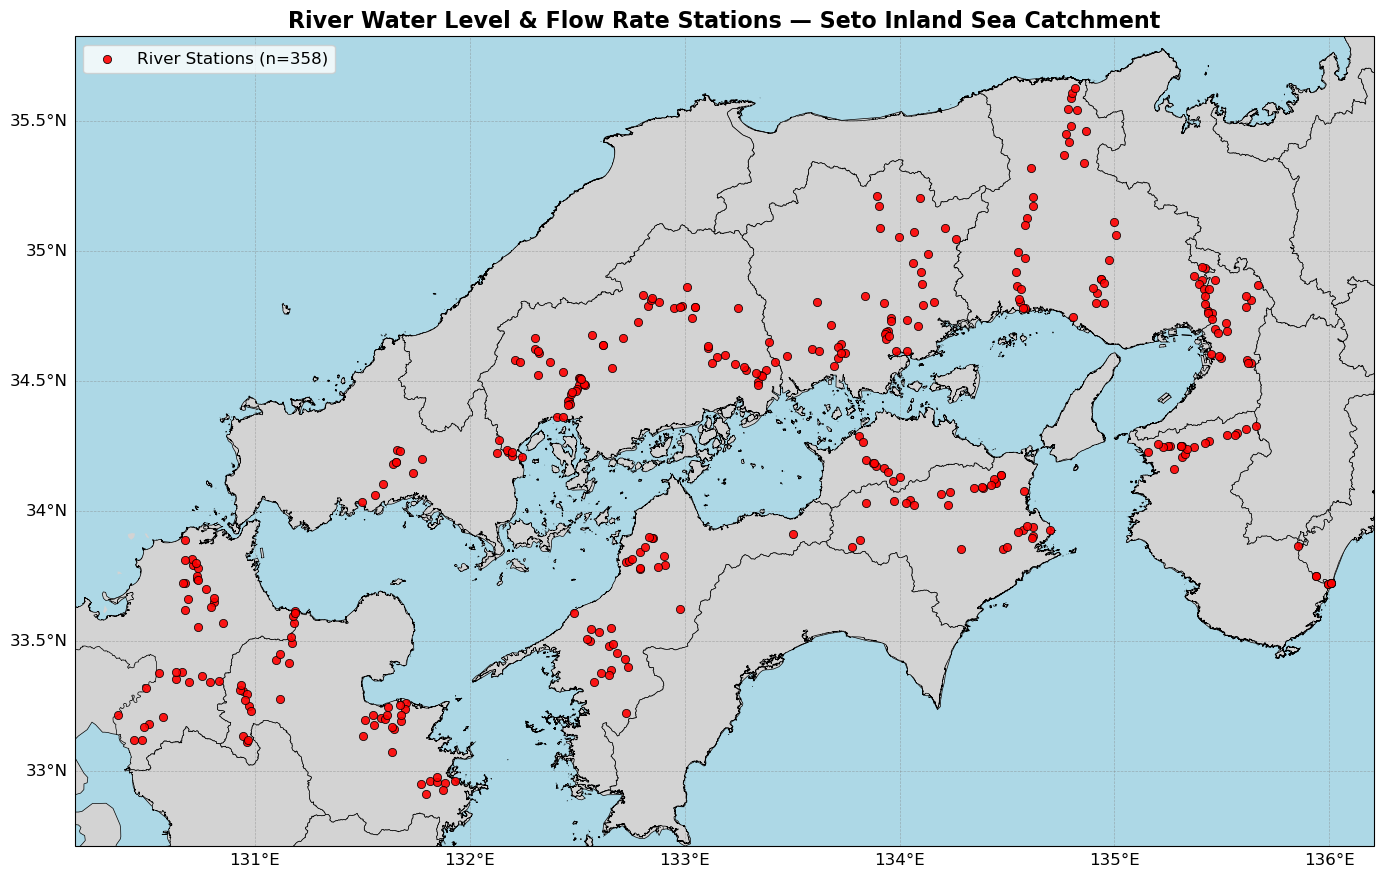

In [4]:
# Create GeoDataFrame
gdf = gpd.GeoDataFrame(
    df_stations,
    geometry=gpd.points_from_xy(df_stations['longitude'], df_stations['latitude']),
    crs='EPSG:4326'
)

# Setup plot
fig, ax = plt.subplots(figsize=(14, 10), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_facecolor(MappingConfig.COLOR_OCEAN)

# Plot background cartopy features
ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)

# Load and plot high-resolution regional boundary shapefile
target_region = 'Seto Inland Sea'
land_boundary_file = MappingConfig.get_boundary_file(target_region)
land_boundary_path = ProjectPaths.BOUNDARIES_DIR / 'SIS_prefecture_boundaries' / land_boundary_file

if land_boundary_path.exists():
    sis_land = gpd.read_file(land_boundary_path)
    if sis_land.crs != 'EPSG:4326':
        sis_land = sis_land.to_crs('EPSG:4326')
    sis_land.plot(
        ax=ax,
        facecolor=MappingConfig.COLOR_LAND,
        edgecolor=MappingConfig.COLOR_LAND_EDGE,
        linewidth=MappingConfig.LINEWIDTH_LAND,
        transform=ccrs.PlateCarree(),
        zorder=MappingConfig.ZORDER_LAND
    )

# Add gridlines
gl = ax.gridlines(draw_labels=True,
                  linestyle=MappingConfig.GRID_LINESTYLE,
                  color=MappingConfig.GRID_COLOR,
                  alpha=MappingConfig.GRID_ALPHA,
                  linewidth=MappingConfig.GRID_LINEWIDTH,
                  zorder=MappingConfig.ZORDER_GRIDLINES)
gl.top_labels = False
gl.right_labels = False

# Plot river stations
gdf.plot(
    ax=ax,
    color='red',
    markersize=35,
    edgecolor='black',
    linewidth=0.6,
    alpha=0.9,
    transform=ccrs.PlateCarree(),
    zorder=MappingConfig.ZORDER_OBSERVATIONS,
    label=f'River Stations (n={len(gdf)})'
)

# Set dynamic extent with a 0.2-degree buffer
bounds = gdf.total_bounds
ax.set_extent([
    bounds[0] - 0.2,
    bounds[2] + 0.2,
    bounds[1] - 0.2,
    bounds[3] + 0.2
], crs=ccrs.PlateCarree())

plt.title(f'River Water Level & Flow Rate Stations — {target_region} Catchment', fontsize=16, fontweight='bold')
plt.legend(loc='upper left', fontsize=12)

plt.tight_layout()
plt.show()